
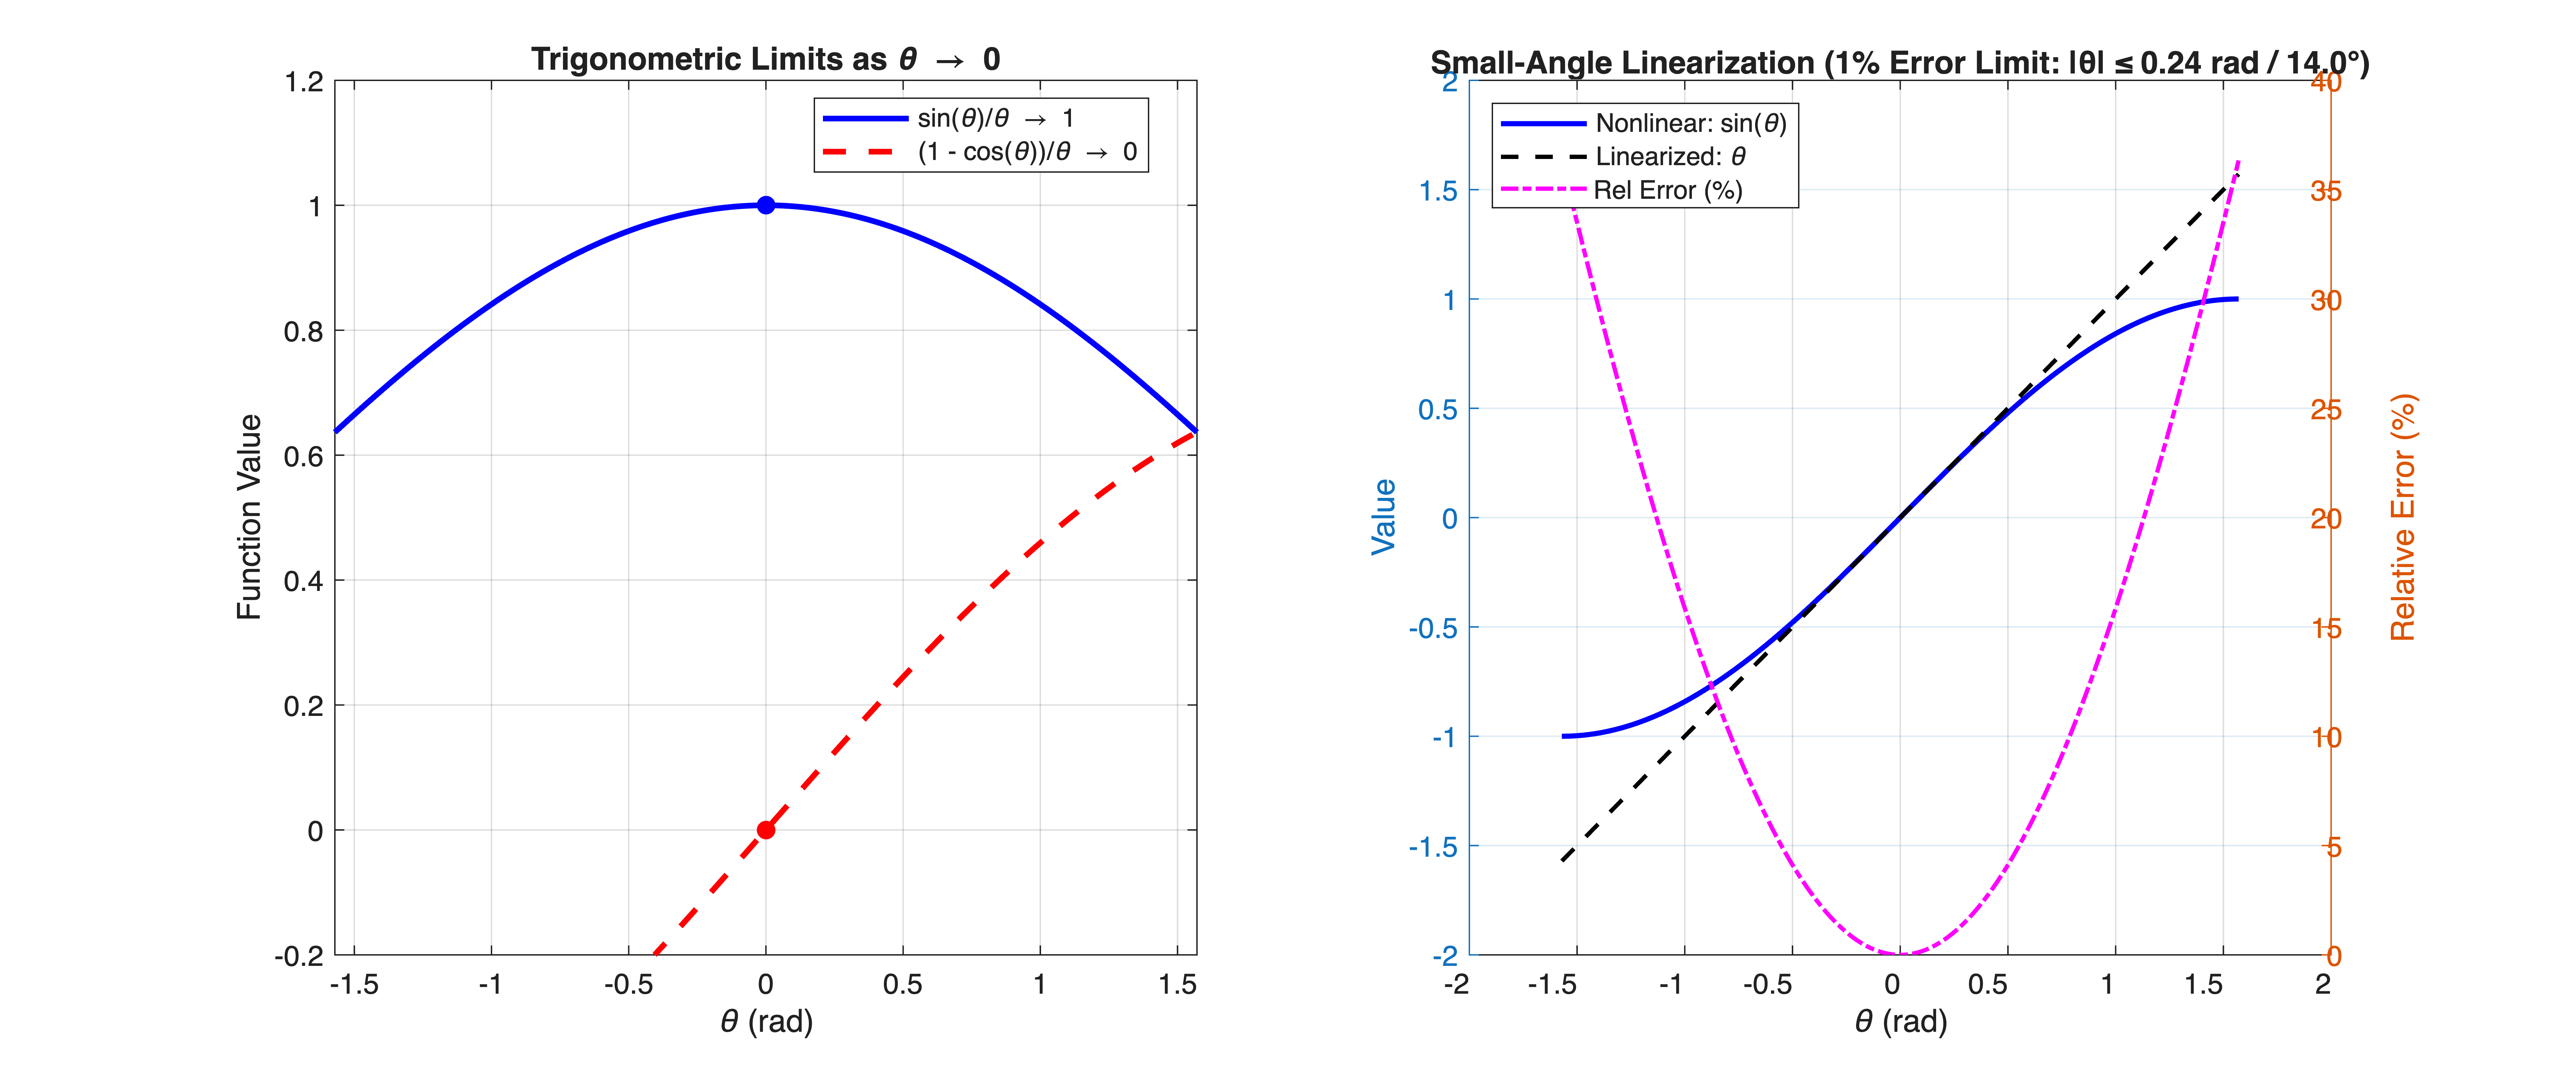

In [1]:
clear; clc; close all;


%% Part 1: Trigonometric Limits and Small-Angle Linearization
% Angle sweep around zero in radians
theta = linspace(-pi/2, pi/2, 1000);
theta_nonzero = theta(theta ~= 0);


% Difference quotients for trig limits
limit_sin = sin(theta_nonzero) ./ theta_nonzero;
limit_cos = (1 - cos(theta_nonzero)) ./ theta_nonzero;


% Relative linearization error: |sin(theta) - theta| / |theta|
rel_error_sin = abs(sin(theta_nonzero) - theta_nonzero) ./ abs(theta_nonzero);


figure('Color', 'w', 'Position', [100, 100, 1200, 500]);


subplot(1, 2, 1);
plot(theta_nonzero, limit_sin, 'b-', 'LineWidth', 2, 'DisplayName', 'sin(\theta)/\theta \rightarrow 1'); hold on;
plot(theta_nonzero, limit_cos, 'r--', 'LineWidth', 2, 'DisplayName', '(1 - cos(\theta))/\theta \rightarrow 0');
plot(0, 1, 'bo', 'MarkerFaceColor', 'b', 'HandleVisibility', 'off');
plot(0, 0, 'ro', 'MarkerFaceColor', 'r', 'HandleVisibility', 'off');


grid on;
xlabel('\theta (rad)');
ylabel('Function Value');
title('Trigonometric Limits as \theta \rightarrow 0');
legend('Location', 'best');
xlim([-pi/2, pi/2]);
ylim([-0.2, 1.2]);


% Linearization validity region (<= 1% relative error threshold)
threshold_1pct = 0.01;
theta_valid = theta_nonzero(rel_error_sin <= threshold_1pct);
max_linear_angle = max(theta_valid);


subplot(1, 2, 2);
yyaxis left;
plot(theta, sin(theta), 'b-', 'LineWidth', 1.8, 'DisplayName', 'Nonlinear: sin(\theta)'); hold on;
plot(theta, theta, 'k--', 'LineWidth', 1.5, 'DisplayName', 'Linearized: \theta');
ylabel('Value');
xlabel('\theta (rad)');


yyaxis right;
plot(theta_nonzero, rel_error_sin * 100, 'm-.', 'LineWidth', 1.5, 'DisplayName', 'Rel Error (%)');
ylabel('Relative Error (%)');
title(sprintf("Small-Angle Linearization (1%% Error Limit: |θ| ≤ %.2f rad / %.1f°)", ...
    max_linear_angle, rad2deg(max_linear_angle)), ...
    'Interpreter', 'none');


grid on;
legend('Location', 'northwest');


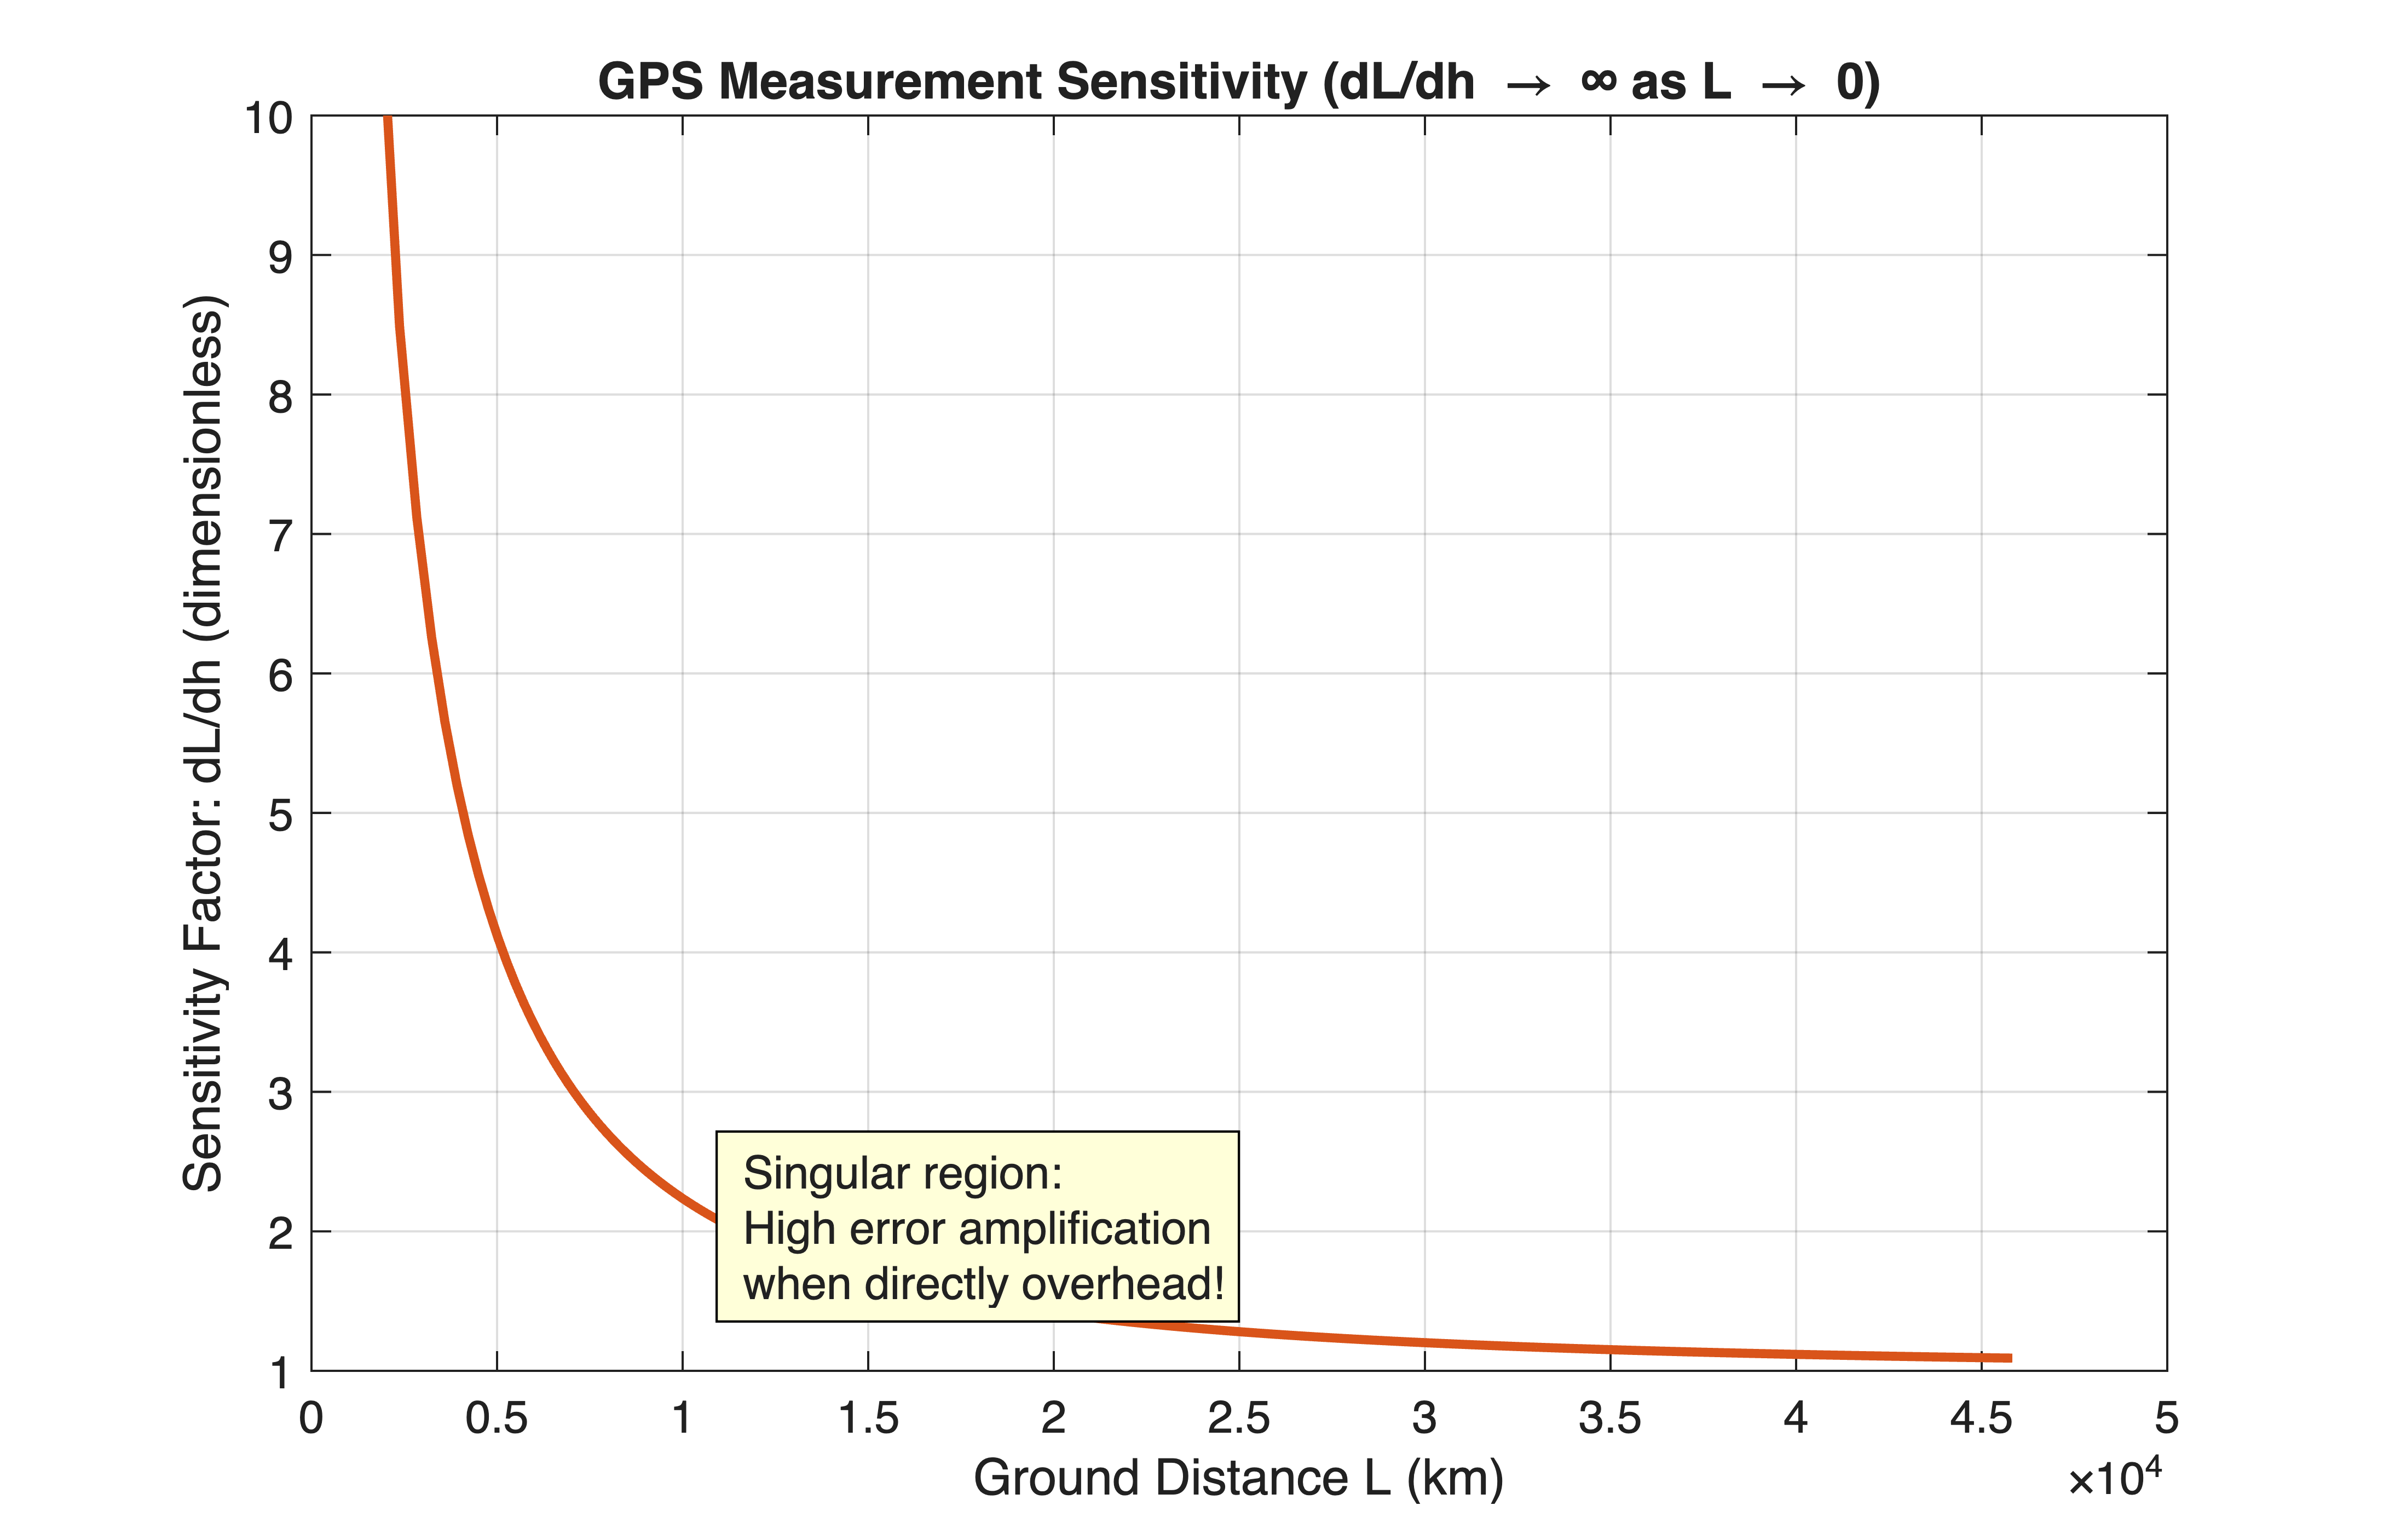

In [2]:


%% Part 2: GPS Slant-Range Sensitivity Analysis (Flat Earth Model)
% Relationship: h^2 = s^2 + L^2 => L = sqrt(h^2 - s^2)
% Sensitivity: dL/dh = h / sqrt(h^2 - s^2) = h / L
s_altitude = 20000; % Satellite altitude: 20,000 km (typical GPS orbit)
h_range = linspace(s_altitude * 1.001, s_altitude * 2.5, 500);


L_ground = sqrt(h_range.^2 - s_altitude^2);
dL_dh = h_range ./ L_ground;


figure('Color', 'w', 'Position', [150, 150, 700, 450]);
plot(L_ground, dL_dh, 'LineWidth', 2, 'Color', [0.85, 0.33, 0.1]);
grid on;
xlabel('Ground Distance L (km)');
ylabel('Sensitivity Factor: dL/dh (dimensionless)');
title('GPS Measurement Sensitivity (dL/dh \rightarrow \infty as L \rightarrow 0)');
ylim([1, 10]);


text(L_ground(50), dL_dh(50), ...
    sprintf(' Singular region:\n High error amplification\n when directly overhead!'), ...
    'BackgroundColor', [1 1 0.85], 'EdgeColor', 'k');